# Complex analysis 4: Cauchy's theorem and the integral formula

*Learning path: complex analysis, part 4 of 8.* [Index](README.md) · Previous: [Contour integrals](03-contour-integrals.ipynb) · Next: [Taylor and Laurent series](05-taylor-and-laurent.ipynb)

Here is a claim that has no counterpart in real calculus: if you know an analytic function on a circle, you know it
everywhere inside. Not approximately, exactly, and all its derivatives too. The values on the boundary determine the
values in the interior through one integral, Cauchy's formula. From it follow, in a few lines each, that analytic
functions have derivatives of every order, that a bounded function analytic on the whole plane is constant, and that
every polynomial has a root. This lesson walks that chain.

**Who this is for.** You have done [lesson 3](03-contour-integrals.ipynb) and can compute $\oint f\,dz$ with `cint`.

**What you will be able to do afterwards:**

1. state Cauchy's theorem, say why it follows from the Cauchy–Riemann equations, and deform contours with it;
2. evaluate integrals like $\oint e^z/(z - a)\,dz$ with Cauchy's integral formula;
3. compute derivatives as integrals, and explain why analytic functions are infinitely differentiable;
4. prove Liouville's theorem and, from it, the fundamental theorem of algebra.

Plan about an hour.

## 1. Cauchy's theorem

**Cauchy's theorem.** If $f$ is analytic on and inside a closed loop $\gamma$, then $\oint_\gamma f\,dz = 0$.

Why: write $f\,dz = (u + iv)(dx + i\,dy) = (u\,dx - v\,dy) + i(v\,dx + u\,dy)$. Green's theorem turns each line integral
into an area integral over the inside $D$:

$$\oint_\gamma f\,dz = \iint_D (-v_x - u_y)\,dA + i\iint_D (u_x - v_y)\,dA,$$

and both integrands vanish by the Cauchy–Riemann equations. Test it on $e^z/(z - 3)$, whose only problem is at $z = 3$,
outside the unit circle:

In [1]:
cint(exp(z)/(z - 3), z, exp(i*t), t, 0, 2*pi)
cint(1/(z^2 + 1), z, (1 + i)/2 + exp(i*t)/4, t, 0, 2*pi)

0.0

> Contour integral of f dz along z = exp(i*t), t from 0 to 2*pi: the integral of f(z(t)) z'(t) dt, computed numerically with Simpson's rule on 4096 steps.

0.0

> Contour integral of f dz along z = 1/2+exp(i*t)/4+i/2, t from 0 to 2*pi: the integral of f(z(t)) z'(t) dt, computed numerically with Simpson's rule on 4096 steps.

Both are 0. When the loop does enclose a singularity, the theorem still says something: you may **deform** the loop
without crossing a singularity and the integral does not change, because the region between the two loops contains
none. That is why, in lesson 3, every loop around the origin gave $\oint dz/z = 2\pi i$. A loop around both $\pm i$
gives the sum of two small loops, one around each, which here cancel:

In [2]:
cint(1/(z^2 + 1), z, 3*exp(i*t), t, 0, 2*pi)
cint(1/(z^2 + 1), z, i + exp(i*t)/2, t, 0, 2*pi)
cint(1/(z^2 + 1), z, -i + exp(i*t)/2, t, 0, 2*pi)

0.0

> Contour integral of f dz along z = 3*exp(i*t), t from 0 to 2*pi: the integral of f(z(t)) z'(t) dt, computed numerically with Simpson's rule on 4096 steps.

3.14159265359

> Contour integral of f dz along z = exp(i*t)/2+i, t from 0 to 2*pi: the integral of f(z(t)) z'(t) dt, computed numerically with Simpson's rule on 4096 steps.

-3.14159265359

> Contour integral of f dz along z = exp(i*t)/2-i, t from 0 to 2*pi: the integral of f(z(t)) z'(t) dt, computed numerically with Simpson's rule on 4096 steps.

**Try this.** Compute $\oint dz/(z(z - 2))$ around $|z| = 1$ and around $|z| = 3$. Use partial fractions,
$\frac{1}{z(z - 2)} = \frac12\left(\frac{1}{z - 2} - \frac1z\right)$, to predict both answers first.

## 2. Cauchy's integral formula

Now put a singularity in on purpose. If $f$ is analytic on and inside $\gamma$ and $a$ is inside, then

$$f(a) = \frac{1}{2\pi i}\oint_\gamma \frac{f(z)}{z - a}\,dz.$$

The reason: shrink $\gamma$ to a tiny circle around $a$ (allowed by section 1). On it $f(z) \approx f(a)$, and
$\oint dz/(z - a) = 2\pi i$. Check with $f = e^z$ and $a = \tfrac12$:

In [3]:
c = cint(exp(z)/(z - 1/2), z, exp(i*t), t, 0, 2*pi);
eval(c/(2*pi*i))
eval(exp(1/2))

1.6487212707005257

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

1.6487212707001282

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

The boundary values give the value inside. Take $\gamma$ to be the circle $z = a + re^{it}$; then $dz = ire^{it}\,dt$ and
the formula becomes

$$f(a) = \frac{1}{2\pi}\int_0^{2\pi} f(a + re^{it})\,dt:$$

**the value at the center is the average over the circle** (the mean value property). For $e^z$ at 0, the average of
$e^{e^{it}}$ over a turn is $e^0 = 1$, so its integral over a turn is $2\pi$:

In [4]:
integrate(exp(exp(i*t)), t, 0, 2*pi)

6.283185307179586-4.111125665625857e-17*i

> `integrate`: Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

An average can't be larger than every value it averages, so $|f|$ can't have a maximum inside a region unless $f$ is
constant: the **maximum modulus principle**. The largest value of $|f|$ on a closed disc is always on its edge.

**Try this.** Evaluate $\oint \sin z/(z - \pi/2)\,dz$ around $|z| = 2$ with the formula, then check with `cint`.

## 3. Derivatives of every order

Differentiate the integral formula with respect to $a$, under the integral sign. Each derivative brings down one more
factor of $1/(z - a)$:

$$f^{(n)}(a) = \frac{n!}{2\pi i}\oint_\gamma \frac{f(z)}{(z - a)^{n+1}}\,dz.$$

The right-hand side exists for every $n$, so **an analytic function has derivatives of every order**, and each is
analytic. On the real line nothing like this holds. For $e^z$ at 0, every derivative is 1, so
$\oint e^z/z^3\,dz = 2\pi i/2! = \pi i$:

In [5]:
cint(exp(z)/z^3, z, exp(i*t), t, 0, 2*pi)

3.14159265359*i

> Contour integral of f dz along z = exp(i*t), t from 0 to 2*pi: the integral of f(z(t)) z'(t) dt, computed numerically with Simpson's rule on 4096 steps.

and for $\cos z$, whose third derivative $\sin z$ vanishes at 0, $\oint \cos z/z^4\,dz = 0$:

In [6]:
cint(cos(z)/z^4, z, 2*exp(i*t), t, 0, 2*pi)

0.0

> Contour integral of f dz along z = 2*exp(i*t), t from 0 to 2*pi: the integral of f(z(t)) z'(t) dt, computed numerically with Simpson's rule on 4096 steps.

**Try this.** Use the formula to evaluate $\oint e^{2z}/(z - 1)^3\,dz$ around $|z| = 2$, and check with `cint`.

## 4. Liouville's theorem and the fundamental theorem of algebra

Take $\gamma$ to be a circle of radius $R$ around $a$, and suppose $|f| \le M$ on it. The formula for $f'$ and the ML
estimate of lesson 3 give **Cauchy's estimate**

$$|f'(a)| \le \frac{1}{2\pi}\cdot\frac{M}{R^2}\cdot 2\pi R = \frac{M}{R}.$$

If $f$ is analytic on the whole plane (**entire**) and bounded, $|f| \le M$ everywhere, let $R \to \infty$: $f'(a) = 0$
for every $a$, so $f$ is constant. This is **Liouville's theorem**. ($\sin z$ is entire and is bounded on the real line,
but not in the plane, as lesson 1 showed.)

**The fundamental theorem of algebra.** Every polynomial $p$ of degree $\ge 1$ has a complex root. Proof: if $p$ had no
root, $1/p$ would be entire. It is also bounded, because $|p(z)| \to \infty$ as $|z| \to \infty$. By Liouville, $1/p$
would be constant, and so would $p$. Dividing out a root and repeating, a polynomial of degree $n$ has exactly $n$ roots
counted with multiplicity. For $z^3 - z + 1$, which has only one real root:

In [7]:
eval(solve(z^3 - z + 1, z))

[-1.3247179572447458, 0.6623589786223729-0.5622795120623013*i, 0.6623589786223729+0.5622795120623013*i]

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

The domain coloring shows all three as dark points where the colors go once round:

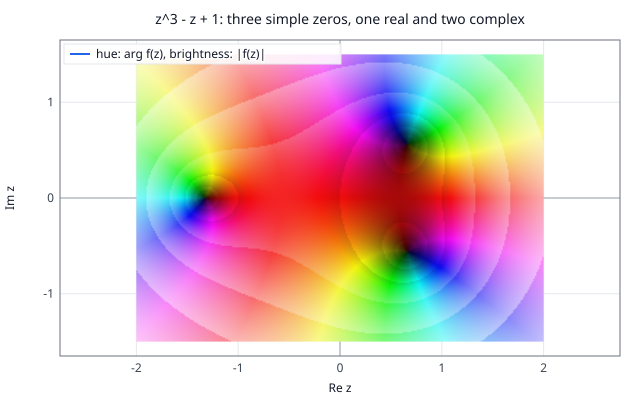

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [8]:
p = cplot(z^3 - z + 1, z, -2, 2, -1.5, 1.5);
labels(title(p, "z^3 - z + 1: three simple zeros, one real and two complex"), "Re z", "Im z")

**Try this.** Why is $e^z$, which is entire and never 0, not a counterexample to the argument above? (Hint: is
$1/e^z$ bounded?)

## Summary

* **Cauchy's theorem:** $\oint_\gamma f\,dz = 0$ when $f$ is analytic on and inside $\gamma$. Loops can be deformed
  without changing the integral, as long as they don't cross a singularity.
* **Cauchy's integral formula:** $f(a) = \frac{1}{2\pi i}\oint f(z)/(z - a)\,dz$; in particular $f(a)$ is the average of
  $f$ over any circle around $a$, and $|f|$ takes its maximum on the boundary.
* $f^{(n)}(a) = \frac{n!}{2\pi i}\oint f(z)/(z - a)^{n+1}\,dz$: analytic functions are infinitely differentiable.
* **Liouville:** a bounded entire function is constant. Hence every polynomial of degree $n$ has $n$ complex roots.

Next: [Taylor and Laurent series](05-taylor-and-laurent.ipynb), where the integral formula turns into power series.

## Exercises

1. **Partial fractions.** Evaluate $\oint dz/(z^2 - 1)$ around $|z - 1| = 1$, around $|z + 1| = 1$ and around $|z| = 2$.
2. **Integral formula.** Evaluate $\oint z^2/(z - i)\,dz$ around $|z| = 2$.
3. **Second derivative.** Evaluate $\oint \sin z/z^3\,dz$ around $|z| = 1$.
4. **Maximum modulus.** Where on the closed unit disc does $|z^2 + 2z|$ take its largest value? Check with
   `cplot(z^2 + 2*z, z, -1, 1, -1, 1)`: where is the picture lightest?
5. **Growth.** Show with Cauchy's estimate for the $n$-th derivative, $|f^{(n)}(0)| \le n!\,M/R^n$, that an entire
   function with $|f(z)| \le |z|^2$ for large $|z|$ is a polynomial of degree at most 2.

## Hints and answers

* **Section 1, Try this.** Around $|z| = 1$ only the pole at 0 is inside: $\frac12(0 - 2\pi i) = -\pi i$. Around
  $|z| = 3$ both are, and they cancel: 0.
* **Section 2, Try this.** $2\pi i \sin(\pi/2) = 2\pi i$. `cint(sin(z)/(z - pi/2), z, 2*exp(i*t), t, 0, 2*pi)` gives
  $6.283\ldots i$.
* **Section 3, Try this.** $f = e^{2z}$, $f'' = 4e^{2z}$, so the integral is $\frac{2\pi i}{2!}\cdot 4e^2 = 4\pi e^2 i$.
  `cint(exp(2*z)/(z - 1)^3, z, 2*exp(i*t), t, 0, 2*pi)` gives $92.85\ldots i$.
* **Section 4, Try this.** The proof needs $1/p$ to be bounded, which comes from $|p| \to \infty$. $|e^z| = e^x$ tends
  to 0 as $x \to -\infty$, so $1/e^z = e^{-z}$ is unbounded.
* **Exercise 1.** $\frac{1}{z^2 - 1} = \frac12\left(\frac{1}{z - 1} - \frac{1}{z + 1}\right)$: $\pi i$, $-\pi i$ and 0.
* **Exercise 2.** $2\pi i \cdot i^2 = -2\pi i$.
* **Exercise 3.** $\frac{2\pi i}{2!}\sin''(0) = -\pi i \sin 0 = 0$.
* **Exercise 4.** At $z = 1$, where it is 3. On the circle $|z^2 + 2z| = |z + 2|$, largest at $z = 1$.
* **Exercise 5.** For $n \ge 3$, $|f^{(n)}(0)| \le n!\,R^2/R^n \to 0$, so the Taylor series of lesson 5 stops at $z^2$.

## Sources

1. A. L. Cauchy, *Mémoire sur les intégrales définies prises entre des limites imaginaires* (1825); the integral
   formula in *Exercices d'analyse et de physique mathématique* (1841).
2. J. Liouville (1844), as reported by C. W. Borchardt, *Journal für die reine und angewandte Mathematik* 88 (1880).
3. E. M. Stein and R. Shakarchi, *Complex Analysis*, Princeton University Press (2003), chapter 2.
4. T. Needham, *Visual Complex Analysis*, Oxford University Press (1997), chapter 9.